<h1><center> Prediksi Indeks Performa Akademik Seorang Siswa - 
Machine Learning </center></h1>

Dataset: Student_Performance.csv <br>
Link Dataset: https://www.kaggle.com/datasets/nikhil7280/student-performance-multiple-linear-regression<br>

<b> Deskripsi: </b><br>
Projek ini memliki tujuan untuk memprediksi indeks performa siswa berdasarkan kebiasaan belajar dan latar belakangnya<br>


<h2><center> Membaca dataset </center></h2>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Student_Performance.csv")

df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


<li>pandas: mengolah dataset dalam bentuk tabel</li>
<li>numpy: membantu operasi numerik</li>
<li>matplotlib.pyplot: membuat grafik</li>
<li>seaborn: membuat visualisasi statistik</li>
<li>df.head(): membaca 5 baris pertama



Penjelasan setiap fitur:
<li>Hours Studied: Jam belajar</li>
<li>Previous Scores: Nilai sebelumnya</li>
<li>Extracurricular Activities: Keikutsertaan dalam kegiatan ekstrakurikuler</li>
<li>Sleep Hours: Durasi tidur</li>
<li>Sample Question Papers Practiced: Jumlah lathan soal yang dikerjakan</li>
<li>Performance Index: Target berupa indeks performa siswa</li>

<h2><center> Data Cleaning </center></h2>

In [2]:
# Menampilkan ukuran dataset
print("Ukuran dataset:", df.shape)

# Menampilkan informasi kolom dan tipe data
df.info()


Ukuran dataset: (10000, 6)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB


kode ini digunakan untuk mengetahui jumlah baris, kolom, tipe data, dan jumlah nlai yang terisi.

<b>Hasil:</b> datset berisi 10.000 baris dan 6 kolom. 5 kolom bertipe numerik, sedangkan extracurricular activities bertipe string (teks)

In [3]:
# Menampilkan statistik deskriptif
display(df.describe(include="all"))

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000,10000.000000,10000.000000,10000.000000
unique,NaN,NaN,2,NaN,NaN,NaN
top,NaN,NaN,No,NaN,NaN,NaN
freq,NaN,NaN,5052,NaN,NaN,NaN
mean,4.992900,69.445700,NaN,6.530600,4.583300,55.224800
std,2.589309,17.343152,NaN,1.695863,2.867348,19.212558
min,1.000000,40.000000,NaN,4.000000,0.000000,10.000000
25%,3.000000,54.000000,NaN,5.000000,2.000000,40.000000
50%,5.000000,69.000000,NaN,7.000000,5.000000,55.000000
75%,7.000000,85.000000,NaN,8.000000,7.000000,71.000000


<b>Hasil:</b> menampilkankan statistik seperti jumlah data yang tersedia (count), nilai rata rata (mean), penyebaran data (std), dll.

Hasil statistik yang didapat adalah dataset murni sebelum dibersihkan

In [4]:
# Memeriksa nama kolom
print(df.columns)


Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='str')


### 1. Mencari missing value 

In [5]:
#periksa missing value
print(df.isnull().sum())

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64


<b>Hasil:</b> Tidak ditemukan nilai kosong sama sekali pada keenam kolom, jadi tidak perlu menghapus baris atau mengisi nilai kosong

### 2. Mengatasi Duplikasi Data

Kode yang digunakan:
* duplicated() memeriksa apakah suatu baris memiliki isi yang identik dengan baris sebelumnya
* sum() menghitung jumlah baris yang terdeteksi sebagai duplikat
* df[duplicates] menampilkan baris-baris tersebut agar bisa diperiksa

In [6]:
#memeriksa data duplikat
print("Jumlah data duplikat:", df.duplicated().sum())

# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Jumlah data duplikat: 127
Baris duplikat:
      Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
915               9               52                         No            5   
1477              7               61                        Yes            6   
1601              5               99                         No            7   
1786              2               62                        Yes            9   
2026              5               87                        Yes            6   
...             ...              ...                        ...          ...   
9644              4               91                        Yes            4   
9940              8               95                         No            5   
9954              6               97                         No            8   
9966              1               41                         No            7   
9985              8               99                         No            5  

<b>Hasil yang didapat: 127</b>baris yang ditemukan duplikat <br>
Untuk menghindari baris identik muncul pada data training dan testing harus menghapus duplikasinya

In [7]:
# Membersihkan data duplikasi
df = df.drop_duplicates().copy()

print("Ukuran data setelah cleaning:", df.shape)

Ukuran data setelah cleaning: (9873, 6)



<li><b>Penjelasan hasil:</b> Dataset menjadi 9.873 baris dan 6 kolom. Pembersihan ini mengurangi risiko baris identik muncul pada bagian training dan testing setelah data dibagi

### 3. Memeriksa Outlier </center><h2>

Numerik     : ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']
Kategorikal : ['Extracurricular Activities']


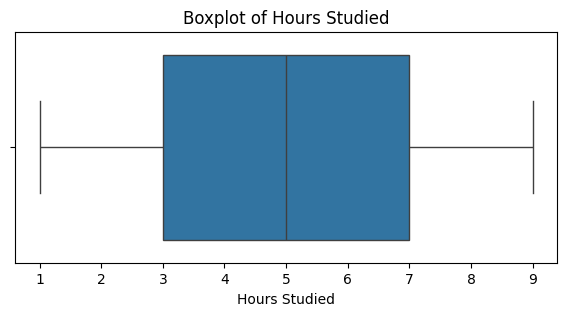

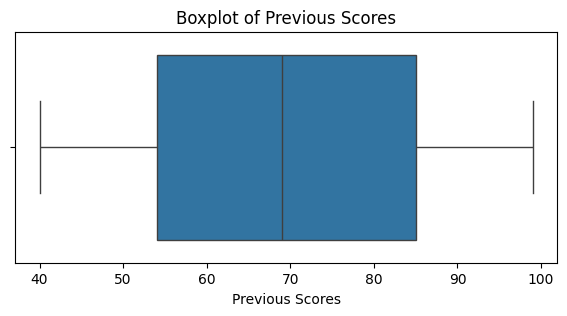

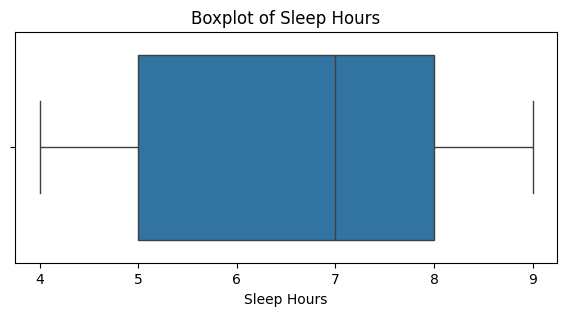

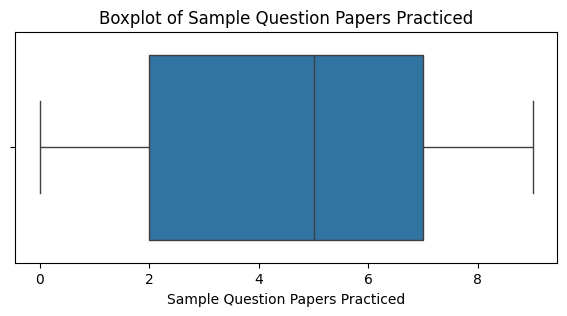

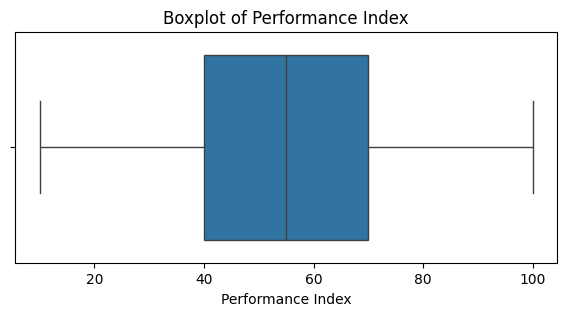

In [8]:
numeric_features = df.select_dtypes(include=["number"]).columns.tolist()
category_features = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("Numerik     :", numeric_features)
print("Kategorikal :", category_features)

for feature in numeric_features:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[feature])
    plt.title(f"Boxplot of {feature}")
    plt.show()

In [9]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [10]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# True = baris tersebut outlier pada kolom terkait
is_outlier = (df[numeric_features] < lower) | (df[numeric_features] > upper)
print("Jumlah outlier per kolom:")
print(is_outlier.sum())
print("\nBaris yang mengandung minimal 1 outlier:", is_outlier.any(axis=1).sum())

Jumlah outlier per kolom:
Hours Studied                       0
Previous Scores                     0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Baris yang mengandung minimal 1 outlier: 0


<b>Hasil:</b> Tidak ditemukan outlier pada seluruh fitur numerik, dan tidak ada baris yanh mengandung setidaknya satu outlier

In [11]:
# Hanya MENYIMPAN baris yang TIDAK mengandung outlier
df = df.loc[~is_outlier.any(axis=1)].reset_index(drop=True)
print("Ukuran data setelah penanganan outlier:", df.shape)

Ukuran data setelah penanganan outlier: (9873, 6)


# <center> Mengonversi Tipe Data (Encoding)

Pada fitur Extracurricular Activities merupakan sebuah string atau teks, maka harus diubah menjadi angka

- **Label Encoding**: mengganti kategori menjadi angka (No=0, Yes=1), jumlah kolom tetap. Dipakai karena kolomnya hanya 2 kategori
- **One Hot Encoding**: membuat kolom baru per kategori. Ditampilkan sebagai pembanding

In [12]:
# Label Encoding untuk kolom kategorikal (Extracurricular Activities: No/Yes)
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()
label_encoders = {}
for col in category_features:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le
    print(f"{col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

df_encoded.head()

Extracurricular Activities: {'No': np.int64(0), 'Yes': np.int64(1)}


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [13]:
# (Pembanding) One Hot Encoding -> kolom baru terbentuk per kategori
pd.get_dummies(df, columns=category_features).head()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index,Extracurricular Activities_No,Extracurricular Activities_Yes
0,7,99,9,1,91.0,False,True
1,4,82,4,2,65.0,True,False
2,8,51,7,2,45.0,False,True
3,5,52,5,2,36.0,False,True
4,7,75,8,5,66.0,True,False


<b>Hasil:</b> 
* No = 0
* Yes = 1

artinya kolom Extracurricular Activities yang awalnya berupa teks skrg sudah menjadi numerik

# <center>EDA


EDA merupakan tahap untuk memahami pola, distribusi, dan hubungan antarvariabel sebelum melatih model

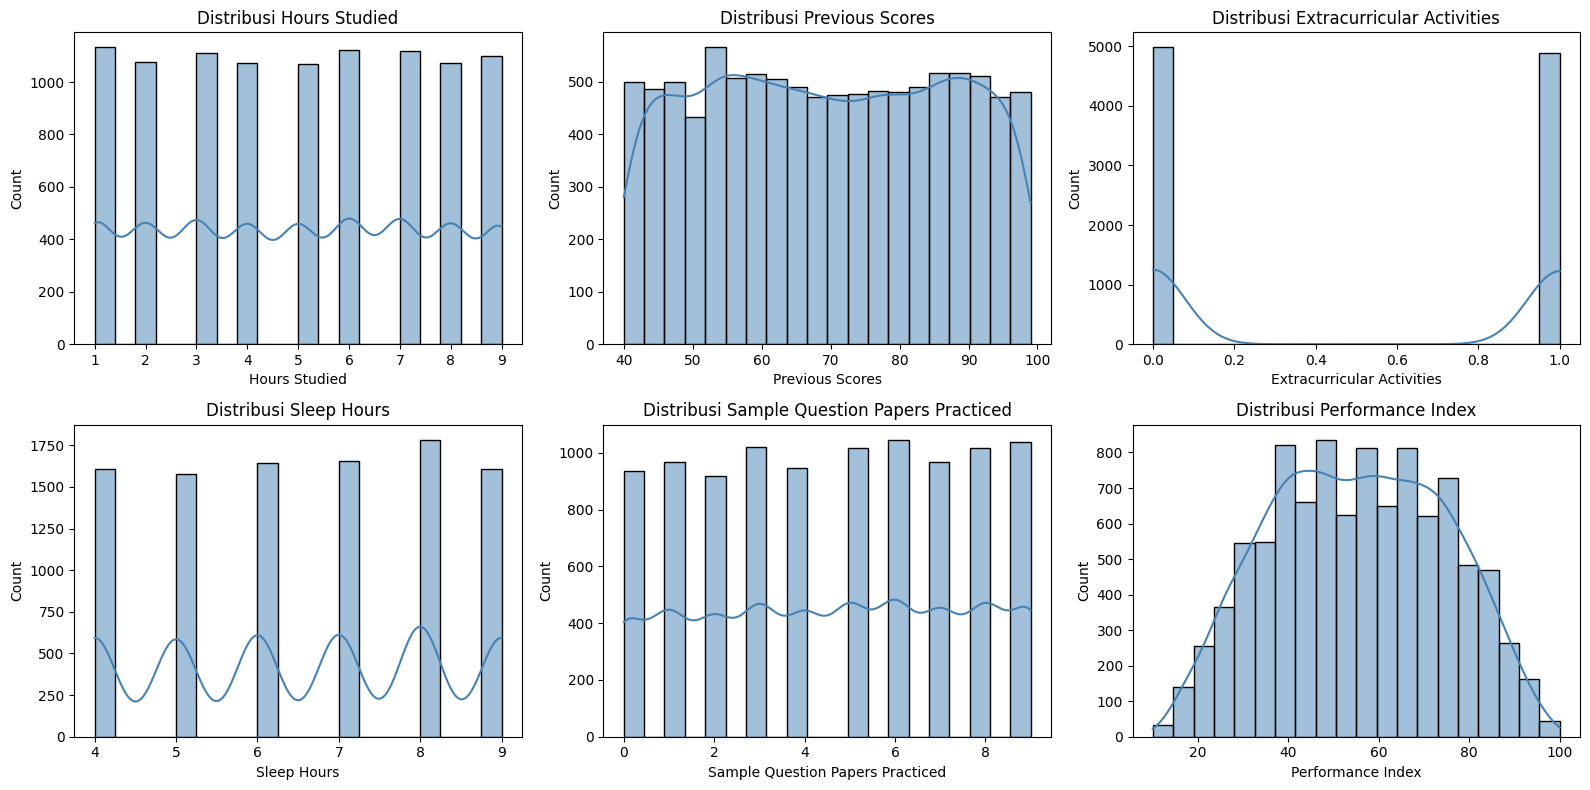

In [14]:
# Distribusi setiap variabel
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for ax, column in zip(axes, df_encoded.columns):
    sns.histplot(df_encoded[column], kde=True, bins=20, ax=ax, color="steelblue")
    ax.set_title(f"Distribusi {column}")
plt.tight_layout()
plt.show()

In [15]:
# Statistik singkat target dan distribusi aktivitas ekstrakurikuler
print(df["Performance Index"].describe())
print()
print(df["Extracurricular Activities"].value_counts())

count    9873.000000
mean       55.216651
std        19.208570
min        10.000000
25%        40.000000
50%        55.000000
75%        70.000000
max       100.000000
Name: Performance Index, dtype: float64

Extracurricular Activities
No     4986
Yes    4887
Name: count, dtype: int64


<b> Hasil: </b> 
* grafik ini digunakan untuk melihat bagaimana nilai setiap fiturnya tersebar dan membantu melihat distribusi target
* Performance index tersebar luas dan relatif simetris di sekitar rata rata 55 tanpa kemiringan ekstrem
* Hours studied, sleep hours, sample question papers pradicted menampilkan histogramnya datar (tiap nilai punya frekuensi mirip)
* Previous scores tersebar dari 40 sampai 99
* Extracurricular Activities hampir seimbang (No 4986 vs Yes 4887)

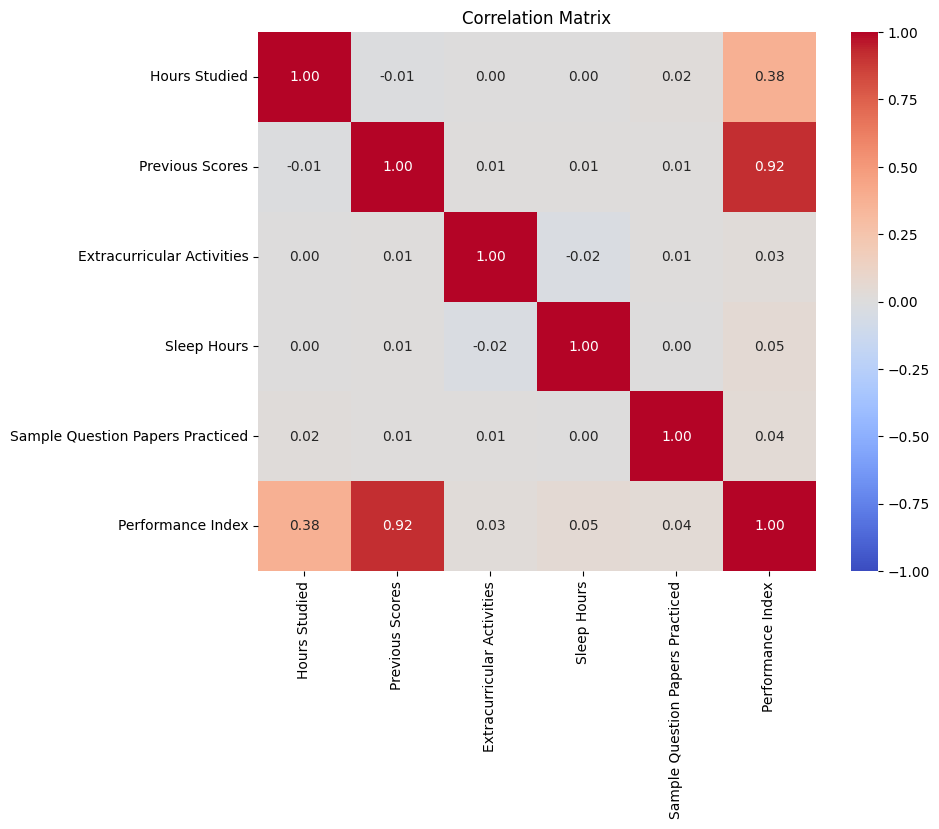

In [16]:
# Heatmap korelasi antar variabel
plt.figure(figsize=(9, 7))
corr = df_encoded.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

<b>Interpretasi: </b> 
* Mendekati 1 : memliki hubungan linier positif yang kuat
* Mendekati -1 : memiliki hubngan linier negatif yang kuat
* Mendekati 0 : hubungan linier yang lemah

<b>Hasil yang di dapat:</b>
* Previous scores dengan Performance index memiliki hubungan linier positif yang kuat
* sedangkan, Performance index dengan hours studied memiliki hubungan linier negatif yang kuat


Previous Scores                     0.9151
Hours Studied                       0.3753
Sleep Hours                         0.0504
Sample Question Papers Practiced    0.0434
Extracurricular Activities          0.0261
Name: Performance Index, dtype: float64


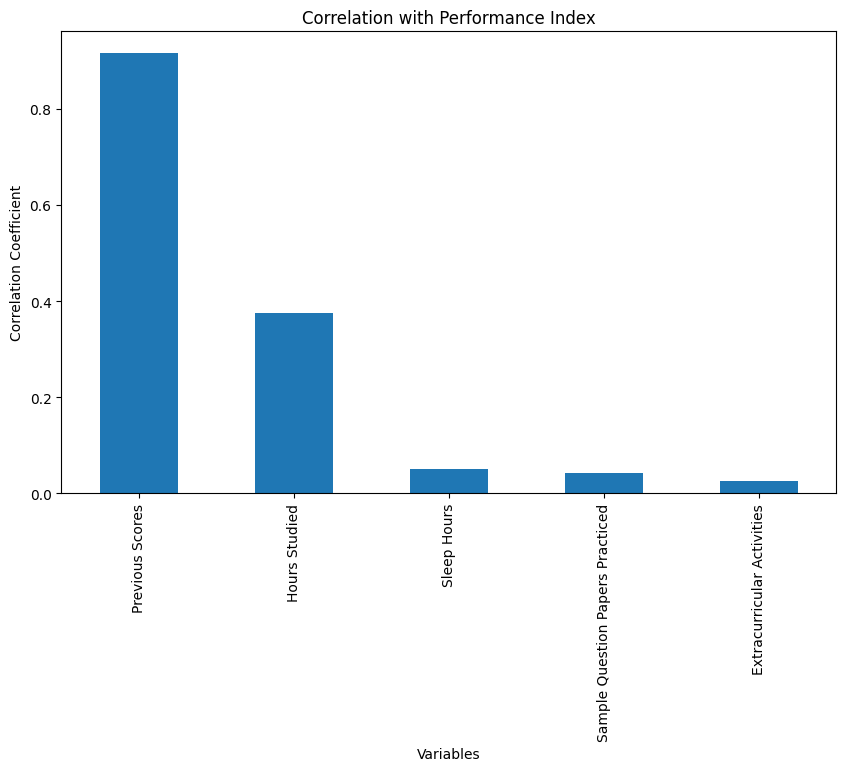

In [17]:
# Korelasi setiap fitur terhadap target (Performance Index)
target_corr = corr["Performance Index"].drop("Performance Index").sort_values(ascending=False)
print(target_corr.round(4))

# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with Performance Index')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

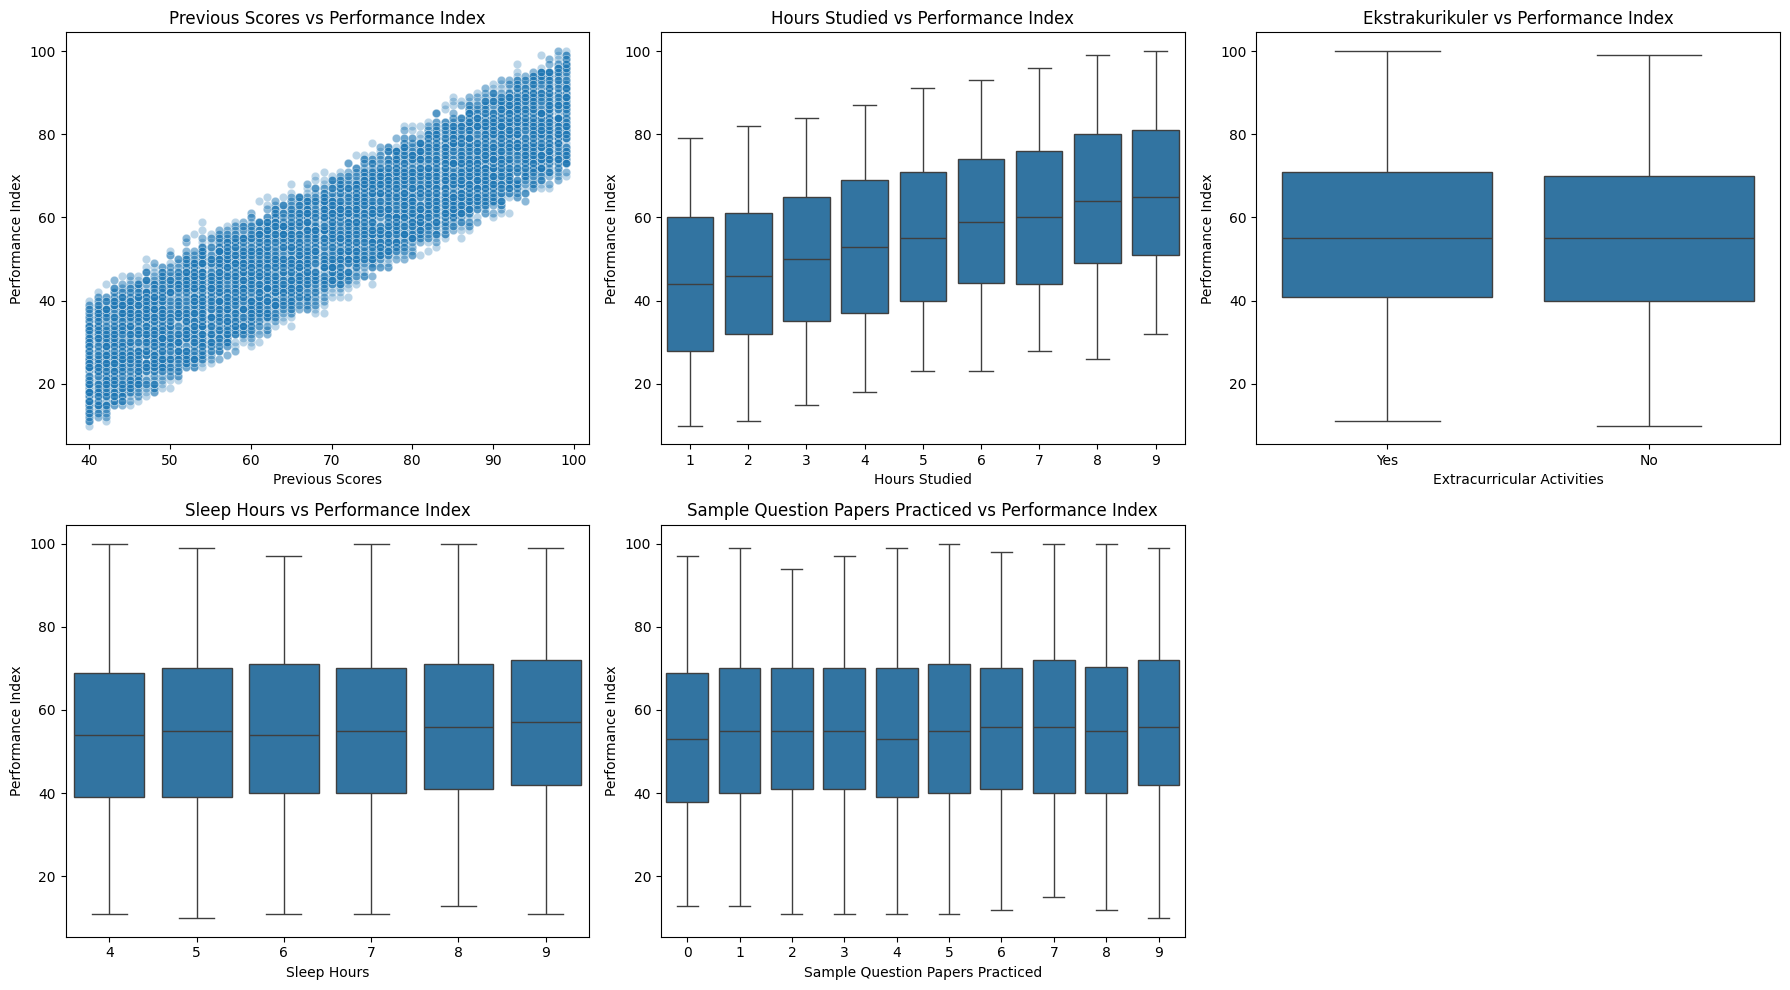

In [18]:
# Hubungan fitur utama dengan target
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

sns.scatterplot(data=df, x="Previous Scores", y="Performance Index", alpha=0.3, ax=axes[0])
axes[0].set_title("Previous Scores vs Performance Index")

sns.boxplot(data=df, x="Hours Studied", y="Performance Index", ax=axes[1])
axes[1].set_title("Hours Studied vs Performance Index")

sns.boxplot(data=df, x="Extracurricular Activities", y="Performance Index", ax=axes[2])
axes[2].set_title("Ekstrakurikuler vs Performance Index")

sns.boxplot(data=df, x="Sleep Hours", y="Performance Index", ax=axes[3])
axes[3].set_title("Sleep Hours vs Performance Index")

sns.boxplot(data=df, x="Sample Question Papers Practiced", y="Performance Index", ax=axes[4])
axes[4].set_title("Sample Question Papers Practiced vs Performance Index")

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

<b> Hasil: </b> 
* Previous Scores (0, 915) korelasi sangat kuat. Scatter plot membentuk pita lurus naik, artinya siswa dengan nilai sebelumnya tinggi hampir pasti punya performa tinggi
* Hours Studied (0,375) korelasi sedang, box plot naik bertahap, makin lama belajar median performa makin tinggi
* Sleep Hours (0,050), Sample Question Papers Practiced (0,043), Extracurricular Activities (0,026): korelasi sangat lemah terhadap target


# <center> Split Data

Untuk memisahkan data yang digunakan melatih model dan data untuk menguji performanya. Pembagian yang digunakan adalah 80% training dan 20% testing

In [19]:
# Memisahkan fitur (X) dan target (y)
X = df_encoded.drop(columns=["Performance Index"])
y = df_encoded["Performance Index"]

from sklearn.model_selection import train_test_split

# Membagi data: 80% latih, 20% uji
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

print("Jumlah data       :", len(X))
print("Jumlah data latih :", len(x_train))
print("Jumlah data test  :", len(x_test))

Jumlah data       : 9873
Jumlah data latih : 7898
Jumlah data test  : 1975


<b> Penjelasan: </b>Model belajar dari 7898 baris data training. setelah itu performanya dinilai menggunakan 1975 baris data testing yang tidak digunakan untuk melatih model

<h2><center>Standarisasi


Untuk menyamakan skala fitur numerik agar memiliki rata-rata sekitar 0 dan standar deviasi sekitar 1. Standardisasi dilakukan berdasarkan data training, lalu diterapkan ke data testing

In [20]:
from sklearn.preprocessing import StandardScaler

# fit HANYA pada data latih, lalu transform ke data latih & uji (mencegah data leakage)
scaler = StandardScaler()
x_train_s = pd.DataFrame(scaler.fit_transform(x_train), columns=X.columns, index=x_train.index)
x_test_s = pd.DataFrame(scaler.transform(x_test), columns=X.columns, index=x_test.index)
 
x_train_s.describe().loc[["mean", "std"]].round(3)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced
mean,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


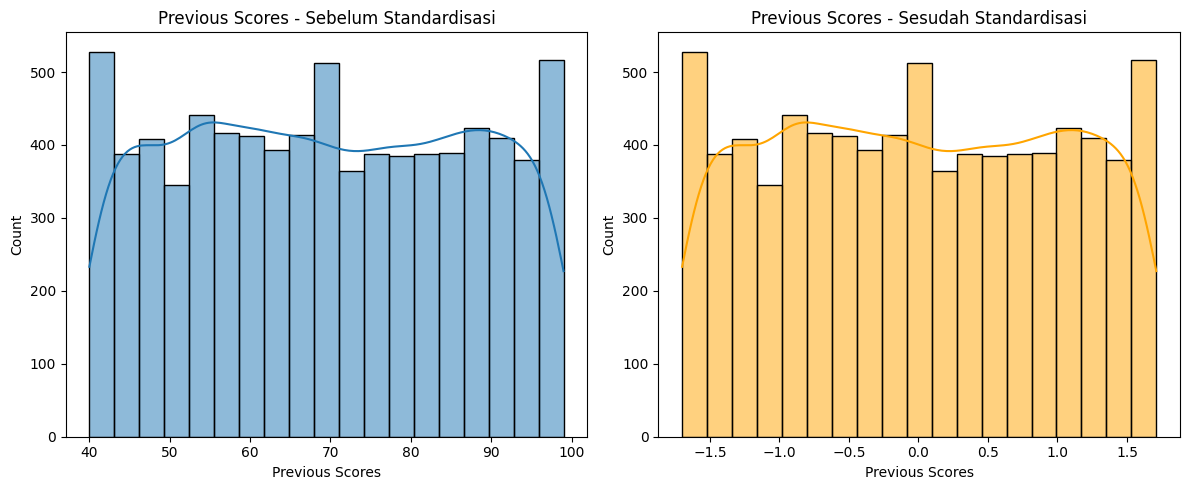

In [21]:
# Histogram sebelum dan sesudah standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(x_train["Previous Scores"], kde=True)
plt.title("Previous Scores - Sebelum Standardisasi")

plt.subplot(1, 2, 2)
sns.histplot(x_train_s["Previous Scores"], kde=True, color="orange")
plt.title("Previous Scores - Sesudah Standardisasi")
plt.tight_layout()
plt.show()

**Hasil:** setelah standarisasi, mean tiap fitur = 0 dan std = 1. Bentuk distribusi tidak berubah, hanya skalanya. Bentuk umum distribusi biasanya tetap sama karena standardisasi merupakan transformasi linear. Tujuannya bukan membuat data menjadi normal, melainkan menyamakan skala fitur

# <center> Pemodelan

## 1. Melatih Model

In [22]:
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor

# Model 1: Least Angle Regression (dibatasi maksimal 1 fitur)
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train_s, y_train)

# Model 2: Linear Regression
LR = LinearRegression().fit(x_train_s, y_train)

# Model 3: Gradient Boosting Regressor
GBR = GradientBoostingRegressor(random_state=184).fit(x_train_s, y_train)

print("Ketiga model selesai dilatih.")

Ketiga model selesai dilatih.


## 2. Evaluasi Model

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test_s)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}
# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

,MAE,MSE,R2
Lars,8.690365,114.221665,0.692901


In [24]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test_s)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results


,MAE,MSE,R2
Lars,8.690365,114.221665,0.692901
Linear Regression,1.613390,4.127106,0.988904


In [25]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test_s)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,8.690365,114.221665,0.692901
Linear Regression,1.613390,4.127106,0.988904
GradientBoostingRegressor,1.645316,4.303487,0.988430


<b>Hasil: </b>
* LARS (MAE 8,69; MSE 114,221; R2 0,69)
* Linier Regression (MAE 1,61; MSE 4,127; R2 0,9889)
* GBR (MAE 1,645; MSE 4,303; R2 0,9884)

<b>Penjelasan Hasil:</b><br>
Berdasarkan ketiga metrik tersebut linier regression menjadi model terbaik dari model yg sudah diuji pada data ini. Model ini memiliki MAE dan MSE terendah dan R2 tertinggi.

Gradient Boosting memiliki performa yang sangat mendekati linier regression sedangkan LARS tertinggal cukup jauh karena dibatasi hanya 1 fitur, menandakan satu fitur saja tidak cukup untuk memprediksi performa yang baik

## Fitur yang paling berpengaruh

                                  Koefisien LR (terstandardisasi)  \
Previous Scores                                           17.6148   
Hours Studied                                              7.3763   
Sleep Hours                                                0.8242   
Sample Question Papers Practiced                           0.5319   
Extracurricular Activities                                 0.3177   

                                  Importance GBR  
Previous Scores                           0.8493  
Hours Studied                             0.1477  
Sleep Hours                               0.0019  
Sample Question Papers Practiced          0.0008  
Extracurricular Activities                0.0003  


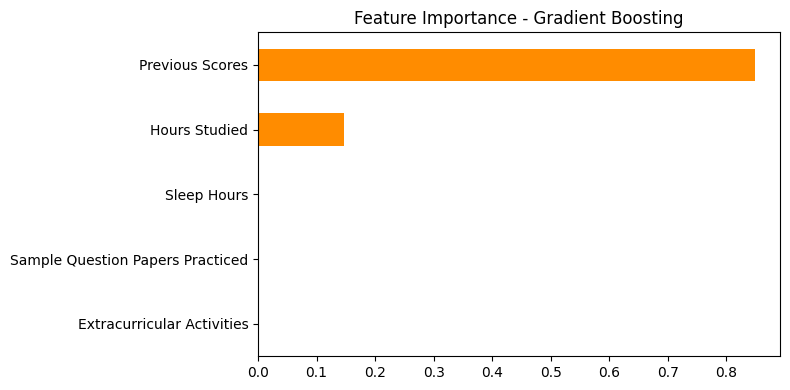

In [26]:
# Pengaruh tiap fitur: koefisien Linear Regression  & importance Gradient Boosting
imp = pd.DataFrame({
    "Koefisien LR (terstandardisasi)": LR.coef_,
    "Importance GBR": GBR.feature_importances_,
}, index=X.columns).sort_values("Importance GBR", ascending=False)

print(imp.round(4))

imp["Importance GBR"].sort_values().plot(kind="barh", figsize=(8, 4), color="darkorange")
plt.title("Feature Importance - Gradient Boosting")
plt.tight_layout()
plt.show()

<b> Hasil yang didapat:</b>
* Previous scores merupakan fitur yang paling dominan pada kedua ukuran. Koefisien linier regression positif dan relatif besar sedangkan important gradient boosting sebesar 0,8493 atau sekitar 84,93%
* Hours Studied, fitur ini memiliki koefisien positif dan important gradient boosting sekitar 14,77%
* Sleep hours, sample question papers praticed, dan extracurricular activities memiliki kontribusi yang jauh lebih kecil 

dengan hasil ini kita dapat ketahui hasil ini menunjukkan bahwa fitur tersebut pling banyak dimanfaatkan model dalam memprediksi target

# <center> Tahap Penyimpanan Model


In [27]:
import joblib

joblib.dump({
    "model": LR,
    "scaler": scaler
}, "student_performance_model.joblib")

['student_performance_model.joblib']

Tujuan: Menyimpan model Linear Regression (LR) dan scaler ke dalam satu file bernama student_performance_model.joblib

In [28]:
data = joblib.load("student_performance_model.joblib")

model = data["model"]
scaler = data["scaler"]

print(model)

LinearRegression()


Tujuan: Membuka file yang sebelumnya disimpan, kemudian mengambil model dan scaler dari dalamnya

## <b>Kesimpulan: </b><br>
Berdasarkan seluruh tahapan yang dilakukan, dataset berhasil untuk memprediksi performance index siswa. Pada tahap processing ditemukan 127 data duplikat yang dihapus sehingga tersisa 9.873 data. Pemeriksaan juga menunjukkan tidak ada missing value maupun outlier pada fitur numerik yang diperiksa

Selanjutnya data kategorikal diubah menjadi numerik menggunakan labelencoder dan one hot coding sebagai alternatif untuk pembanding, melakukan analisis distribusi dan korelasi, kemudian data dibagi menjadi 80% data training dan 20% data testing. 3 model dilatih dan dievaluasi menggunakan MAE, MSE, dan R2

Hasil evaluasi menunjukkan bahwa Linier regression merupakan model terbaik dengan MAE sebesar 1,613; MSE sebesar 4,127; dan R2 sebesar 0,9889. Artinya model memiliki kesalahan prediksi yang relatif kecil dan mampu memprediksi sekitar 98,89% variasi nilai target pada data testing

Berdasarkan analisis fitur previous scores merupakan fitur yang paling dominan dalam prediksi dan diikuti oleh hours studied. Dengan begitu linear regression dapat dipilih sebagai model akhir untuk memprediksi performance index
